# Análise de renda, vegetação e temperatura

## Objetivo

Juntar os indicadores setoriais, comparar quintis de renda e produzir estatísticas, mapas e tabelas da associação entre renda, NDVI e temperatura.

## Entradas

- `sectors_income.gpkg` e `sector_lst_ndvi.csv` produzidos nas etapas anteriores.
- Variáveis de renda, flags territoriais, NDVI e temperatura por setor.

## Saídas

- Tabelas de quintis, correlações, setores extremos e sobreposição.
- Arquivos processados para análise e visualização web.

## Posição no pipeline

É a primeira etapa analítica: transforma as métricas por setor em comparações descritivas e produtos cartográficos.


In [1]:
from pathlib import Path

import geopandas as gpd
import pandas as pd

In [2]:
ROOT = Path.cwd().parent
PROCESSED = ROOT / "data" / "processed"

INCOME_PATH = PROCESSED / "sectors_income.gpkg"
METRICS_PATH = PROCESSED / "sector_lst_ndvi.csv"

## Preparação e junção das tabelas

O objetivo é alinhar a geometria e as métricas pela chave `sector_id`. A padronização da chave evita que diferenças de tipo ou zeros à esquerda criem falsos desencontros.


In [3]:
sectors = gpd.read_file(INCOME_PATH)
metrics = pd.read_csv(METRICS_PATH)

In [4]:
print("Sectors:", sectors.shape)
print("Metrics:", metrics.shape)

print("\nSectors columns:")
print(sectors.columns.tolist())

print("\nMetrics columns:")
print(metrics.columns.tolist())

Sectors: (2310, 16)
Metrics: (2310, 7)

Sectors columns:
['sector_id', 'sector_type', 'area_km2', 'subdistrict', 'favela_name', 'n_households', 'n_residents', 'income_mean', 'income_median', 'income_quintile', 'has_income', 'is_rural', 'small_sector', 'in_rural_zone', 'situation_code', 'geometry']

Metrics columns:
['lst_c', 'lst_valid_dates', 'ndvi', 'ndvi_valid_dates', 'sector_id', 'has_lst', 'lst_data_status']


In [5]:
sectors["sector_id"] = (
    sectors["sector_id"]
    .astype("string")
    .str.zfill(15)
)

metrics["sector_id"] = (
    metrics["sector_id"]
    .astype("string")
    .str.zfill(15)
)

analysis = sectors.merge(
    metrics,
    on="sector_id",
    how="left",
    validate="one_to_one",
)

print("Analysis:", analysis.shape)
print("Missing sector matches:", analysis["lst_data_status"].isna().sum())

Analysis: (2310, 22)
Missing sector matches: 0


In [6]:
print("Valid income:", analysis["has_income"].sum())
print("Valid NDVI:", analysis["ndvi"].notna().sum())
print("Valid LST:", analysis["lst_c"].notna().sum())
print("Missing LST:", analysis["lst_c"].isna().sum())

print("\nLST status:")
print(analysis["lst_data_status"].value_counts(dropna=False))

print("\nIncome quintiles:")
print(analysis["income_quintile"].value_counts(dropna=False).sort_index())

Valid income: 2289
Valid NDVI: 2310
Valid LST: 1787
Missing LST: 523

LST status:
lst_data_status
valid      1787
missing     523
Name: count, dtype: int64

Income quintiles:
income_quintile
1.0    500
2.0    602
3.0    335
4.0    394
5.0    458
NaN     21
Name: count, dtype: int64


## Comparação por quintil

Calculamos tamanho dos grupos, cobertura térmica, NDVI e temperatura por quintil. Os quintis são usados como posições relativas, não como linhas oficiais de pobreza.


In [7]:
quintile_analysis = (
    analysis[analysis["income_quintile"].notna()]
    .groupby("income_quintile")
    .agg(
        n_sectors=("sector_id", "count"),
        n_valid_lst=("lst_c", "count"),
        mean_ndvi=("ndvi", "mean"),
        mean_lst_c=("lst_c", "mean"),
        median_income=("income_median", "median"),
    )
    .reset_index()
)

quintile_analysis

,income_quintile,n_sectors,n_valid_lst,mean_ndvi,mean_lst_c,median_income
0,1.0,500,332,0.286448,38.260906,1300.0
1,2.0,602,426,0.273282,38.422663,2000.0
2,3.0,335,258,0.275321,38.336056,2422.0
3,4.0,394,324,0.259068,38.051541,3000.0
4,5.0,458,427,0.239330,36.515079,7000.0


In [8]:
quintile_analysis["lst_coverage_pct"] = (
    quintile_analysis["n_valid_lst"]
    / quintile_analysis["n_sectors"]
    * 100
).round(1)

quintile_analysis

,income_quintile,n_sectors,n_valid_lst,mean_ndvi,mean_lst_c,median_income,lst_coverage_pct
0,1.0,500,332,0.286448,38.260906,1300.0,66.4
1,2.0,602,426,0.273282,38.422663,2000.0,70.8
2,3.0,335,258,0.275321,38.336056,2422.0,77.0
3,4.0,394,324,0.259068,38.051541,3000.0,82.2
4,5.0,458,427,0.239330,36.515079,7000.0,93.2


In [9]:
lst_distribution = (
    analysis[analysis["income_quintile"].notna()]
    .groupby("income_quintile")["lst_c"]
    .describe(percentiles=[0.25, 0.5, 0.75])
    .round(2)
)

lst_distribution

,count,mean,std,min,25%,50%,75%,max
income_quintile,,,,,,,,
1.0,332.0,38.26,1.46,32.12,37.67,38.45,39.31,41.94
2.0,426.0,38.42,1.36,32.16,37.78,38.61,39.36,41.56
3.0,258.0,38.34,1.36,33.84,37.71,38.63,39.23,41.57
4.0,324.0,38.05,1.30,33.89,37.36,38.20,38.86,41.61
5.0,427.0,36.52,1.54,32.82,35.40,36.57,37.70,41.57


In [10]:
ndvi_distribution = (
    analysis[analysis["income_quintile"].notna()]
    .groupby("income_quintile")["ndvi"]
    .describe(percentiles=[0.25, 0.5, 0.75])
    .round(3)
)

ndvi_distribution

,count,mean,std,min,25%,50%,75%,max
income_quintile,,,,,,,,
1.0,500.0,0.286,0.094,0.096,0.228,0.254,0.322,0.684
2.0,602.0,0.273,0.089,0.109,0.216,0.246,0.302,0.676
3.0,335.0,0.275,0.096,0.082,0.215,0.248,0.324,0.579
4.0,394.0,0.259,0.094,0.078,0.206,0.231,0.282,0.674
5.0,458.0,0.239,0.093,0.102,0.178,0.210,0.271,0.591


## Associação entre renda, NDVI e temperatura

Esta seção calcula correlações de Spearman e distribuições. O objetivo é descrever monotonicidade e diferenças observadas, sem interpretar correlação como causalidade.


In [11]:
income_ndvi = analysis[
    analysis["income_median"].notna()
    & analysis["ndvi"].notna()
]

income_lst = analysis[
    analysis["income_median"].notna()
    & analysis["lst_c"].notna()
]

ndvi_lst = analysis[
    analysis["ndvi"].notna()
    & analysis["lst_c"].notna()
]

correlations = pd.Series(
    {
        "income_vs_ndvi": income_ndvi["income_median"].corr(
            income_ndvi["ndvi"],
            method="spearman",
        ),
        "income_vs_lst": income_lst["income_median"].corr(
            income_lst["lst_c"],
            method="spearman",
        ),
        "ndvi_vs_lst": ndvi_lst["ndvi"].corr(
            ndvi_lst["lst_c"],
            method="spearman",
        ),
    },
    name="spearman_rho",
)

sample_sizes = pd.Series(
    {
        "income_vs_ndvi": len(income_ndvi),
        "income_vs_lst": len(income_lst),
        "ndvi_vs_lst": len(ndvi_lst),
    },
    name="n_sectors",
)

pd.concat([correlations, sample_sizes], axis=1)

,spearman_rho,n_sectors
income_vs_ndvi,-0.238203,2289
income_vs_lst,-0.408733,1767
ndvi_vs_lst,-0.250585,1787


In [12]:
from scipy.stats import spearmanr

correlation_tests = []

for name, data, x, y in [
    ("income_vs_ndvi", income_ndvi, "income_median", "ndvi"),
    ("income_vs_lst", income_lst, "income_median", "lst_c"),
    ("ndvi_vs_lst", ndvi_lst, "ndvi", "lst_c"),
]:
    rho, p_value = spearmanr(data[x], data[y])

    correlation_tests.append(
        {
            "comparison": name,
            "spearman_rho": rho,
            "p_value": p_value,
            "n_sectors": len(data),
        }
    )

correlation_tests = pd.DataFrame(correlation_tests)
correlation_tests

,comparison,spearman_rho,p_value,n_sectors
0,income_vs_ndvi,-0.238203,6.807155e-31,2289
1,income_vs_lst,-0.408733,4.038500e-72,1767
2,ndvi_vs_lst,-0.250585,5.455108e-27,1787


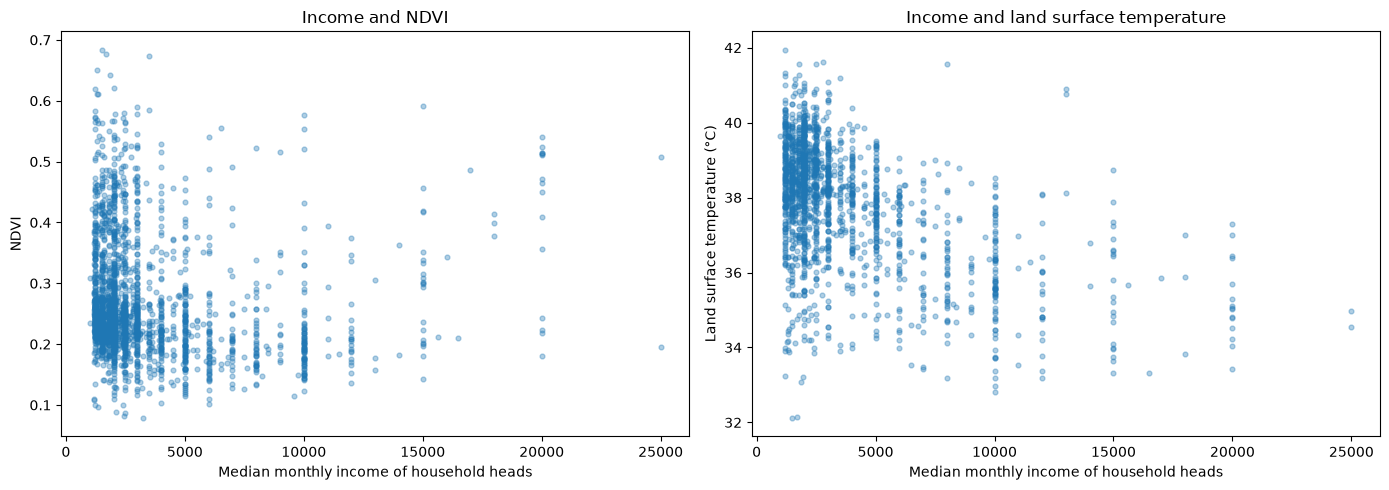

In [13]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    income_ndvi["income_median"],
    income_ndvi["ndvi"],
    alpha=0.35,
    s=12,
)

axes[0].set_title("Income and NDVI")
axes[0].set_xlabel("Median monthly income of household heads")
axes[0].set_ylabel("NDVI")

axes[1].scatter(
    income_lst["income_median"],
    income_lst["lst_c"],
    alpha=0.35,
    s=12,
)

axes[1].set_title("Income and land surface temperature")
axes[1].set_xlabel("Median monthly income of household heads")
axes[1].set_ylabel("Land surface temperature (°C)")

plt.tight_layout()
plt.show()

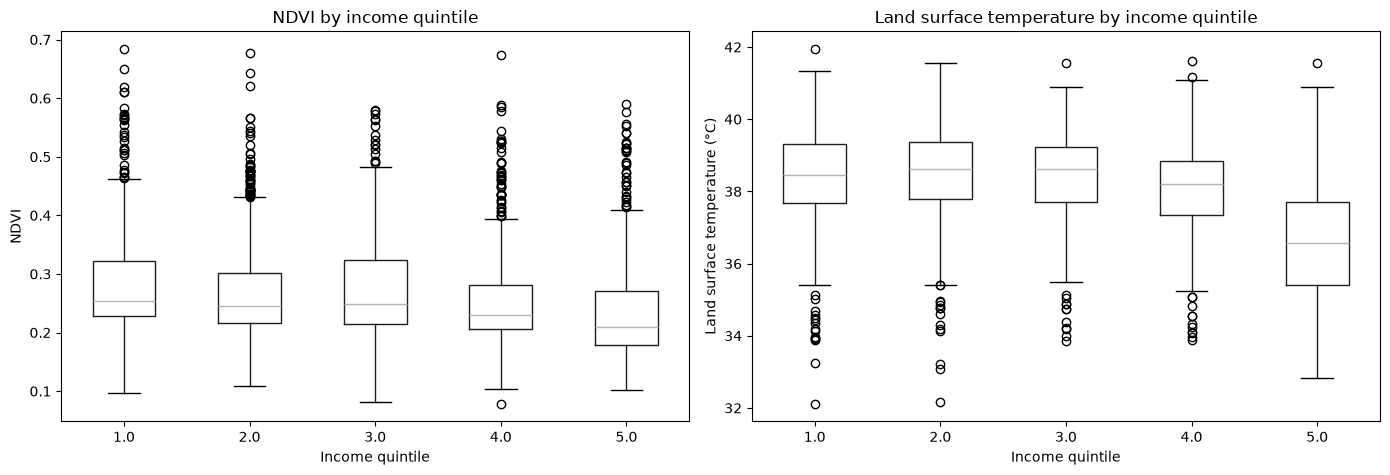

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

analysis.boxplot(
    column="ndvi",
    by="income_quintile",
    ax=axes[0],
    grid=False,
)

axes[0].set_title("NDVI by income quintile")
axes[0].set_xlabel("Income quintile")
axes[0].set_ylabel("NDVI")

analysis.boxplot(
    column="lst_c",
    by="income_quintile",
    ax=axes[1],
    grid=False,
)

axes[1].set_title("Land surface temperature by income quintile")
axes[1].set_xlabel("Income quintile")
axes[1].set_ylabel("Land surface temperature (°C)")

fig.suptitle("")
plt.tight_layout()
plt.show()

## Robustez das comparações

Repetimos resumos com restrições de renda válida, situação urbana e tamanho do setor para verificar quanto os indicadores dependem dessas flags.


In [15]:
robust_analysis = analysis[
    analysis["income_quintile"].notna()
    & ~analysis["is_rural"]
    & ~analysis["small_sector"]
].copy()

robust_quintile_analysis = (
    robust_analysis
    .groupby("income_quintile")
    .agg(
        n_sectors=("sector_id", "count"),
        n_valid_lst=("lst_c", "count"),
        mean_ndvi=("ndvi", "mean"),
        median_ndvi=("ndvi", "median"),
        mean_lst_c=("lst_c", "mean"),
        median_lst_c=("lst_c", "median"),
    )
    .reset_index()
)

robust_quintile_analysis["lst_coverage_pct"] = (
    robust_quintile_analysis["n_valid_lst"]
    / robust_quintile_analysis["n_sectors"]
    * 100
).round(1)

robust_quintile_analysis.round(3)

,income_quintile,n_sectors,n_valid_lst,mean_ndvi,median_ndvi,mean_lst_c,median_lst_c,lst_coverage_pct
0,1.0,495,328,0.285,0.253,38.272,38.451,66.3
1,2.0,594,418,0.271,0.245,38.462,38.623,70.4
2,3.0,330,253,0.272,0.247,38.372,38.659,76.7
3,4.0,386,318,0.260,0.232,38.069,38.215,82.4
4,5.0,421,396,0.243,0.211,36.561,36.596,94.1


In [16]:
# As faixas tornam explícito que renda é tratada como posição/distribuição, não como linha oficial.

analysis["income_band"] = pd.cut(
    analysis["income_median"],
    bins=[0, 2000, 4000, 8000, float("inf")],
    labels=[
        "Up to R$ 2,000",
        "R$ 2,001–4,000",
        "R$ 4,001–8,000",
        "Above R$ 8,000",
        ],
    include_lowest=True,
)

income_band_analysis = (
    analysis[analysis["income_band"].notna()]
    .groupby("income_band", observed=False)
    .agg(
        n_sectors=("sector_id", "count"),
        n_valid_lst=("lst_c", "count"),
        mean_ndvi=("ndvi", "mean"),
        median_ndvi=("ndvi", "median"),
        mean_lst_c=("lst_c", "mean"),
        median_lst_c=("lst_c", "median"),
    )
    .reset_index()
)

income_band_analysis["lst_coverage_pct"] = (
    income_band_analysis["n_valid_lst"]
    / income_band_analysis["n_sectors"]
    * 100
).round(1)

income_band_analysis.round(3)

,income_band,n_sectors,n_valid_lst,mean_ndvi,median_ndvi,mean_lst_c,median_lst_c,lst_coverage_pct
0,"Up to R$ 2,000",1102,758,0.279,0.249,38.352,38.543,68.8
1,"R$ 2,001–4,000",724,578,0.267,0.240,38.180,38.307,79.8
2,"R$ 4,001–8,000",292,266,0.229,0.210,36.986,37.211,91.1
3,"Above R$ 8,000",171,165,0.256,0.210,35.787,35.691,96.5


In [17]:
# O corte de temperatura é um limiar descritivo definido a partir da distribuição observada.

# A sobreposição exige as três condições simultaneamente; não é um novo indicador causal.

valid_ndvi = analysis.loc[
    analysis["income_median"].notna()
    & analysis["ndvi"].notna(),
    "ndvi",
]

valid_lst = analysis.loc[
    analysis["income_median"].notna()
    & analysis["lst_c"].notna(),
    "lst_c",
]

low_ndvi_threshold = valid_ndvi.quantile(0.25)
high_lst_threshold = valid_lst.quantile(0.75)

analysis["low_income"] = analysis["income_quintile"].eq(1)
analysis["low_ndvi"] = analysis["ndvi"].le(low_ndvi_threshold)
analysis["high_lst"] = analysis["lst_c"].ge(high_lst_threshold)

analysis["overlap_thermal_inequality"] = (
    analysis["low_income"]
    & analysis["low_ndvi"]
    & analysis["high_lst"]
)

print(f"Low NDVI threshold: {low_ndvi_threshold:.3f}")
print(f"High LST threshold: {high_lst_threshold:.2f} °C")
print(
    "Overlap sectors:",
    analysis["overlap_thermal_inequality"].sum(),
)

Low NDVI threshold: 0.208
High LST threshold: 38.96 °C
Overlap sectors: 12


## Sobreposição de condições

Marcamos setores que combinam baixa renda, baixa vegetação e alta temperatura para localizar a coincidência das três condições. O resultado é uma seleção descritiva, não um diagnóstico causal.


In [18]:
overlap_sectors = analysis.loc[
    analysis["overlap_thermal_inequality"],
    [
        "sector_id",
        "income_median",
        "income_quintile",
        "ndvi",
        "lst_c",
        "area_km2",
        "sector_type",
        "is_rural",
        "small_sector",
        "subdistrict",
    ],
].sort_values("lst_c", ascending=False)

overlap_sectors

,sector_id,income_median,income_quintile,ndvi,lst_c,area_km2,sector_type,is_rural,small_sector,subdistrict
1708,520870705460022,1500.0,1.0,0.195115,39.917540,0.265289,0,False,False,U.T.P. Urias Magalhães
727,520870705200003,1500.0,1.0,0.188782,39.606568,0.059654,0,False,False,U.T.P. Campinas
1070,520870705290060,1400.0,1.0,0.196888,39.442350,0.035313,0,False,False,U.T.P. Parque das Laranjeiras e Jardim da Luz
1709,520870705460023,1500.0,1.0,0.204050,39.410951,0.078754,0,False,False,U.T.P. Urias Magalhães
735,520870705200011,1210.0,1.0,0.190376,39.384961,0.014716,0,False,False,U.T.P. Campinas
815,520870705220025,1500.0,1.0,0.203044,39.359514,0.056257,0,False,False,U.T.P. Marechal Rondon
752,520870705200030,1200.0,1.0,0.185867,39.345174,0.071012,0,False,False,U.T.P. Campinas
741,520870705200017,1200.0,1.0,0.109113,39.205686,0.107276,0,False,False,U.T.P. Campinas
730,520870705200006,1212.0,1.0,0.100505,39.154539,0.086327,0,False,False,U.T.P. Campinas
1111,520870705310014,1200.0,1.0,0.171434,39.081449,0.042601,0,False,False,U.T.P. Jardim Europa


In [19]:
overlap_eligible = analysis[
    analysis["income_median"].notna()
    & analysis["lst_c"].notna()
    & analysis["ndvi"].notna()
]

overlap_count = overlap_eligible["overlap_thermal_inequality"].sum()
overlap_pct = overlap_count / len(overlap_eligible) * 100

print(f"Eligible sectors: {len(overlap_eligible)}")
print(f"Overlap sectors: {overlap_count}")
print(f"Overlap percentage: {overlap_pct:.2f}%")

print("\nOverlap by subdistrict:")
print(
    overlap_sectors["subdistrict"]
    .value_counts()
    .rename_axis("subdistrict")
    .reset_index(name="n_overlap")
)

Eligible sectors: 1767
Overlap sectors: 12
Overlap percentage: 0.68%

Overlap by subdistrict:
                                     subdistrict  n_overlap
0                                U.T.P. Campinas          5
1                         U.T.P. Urias Magalhães          2
2                           U.T.P. Jardim Europa          2
3  U.T.P. Parque das Laranjeiras e Jardim da Luz          1
4                         U.T.P. Marechal Rondon          1
5                              U.T.P. Zona Rural          1


## Mapas e exportações cartográficas

Os mapas tornam os padrões setoriais verificáveis espacialmente e os arquivos exportados preservam os atributos necessários para reutilização.


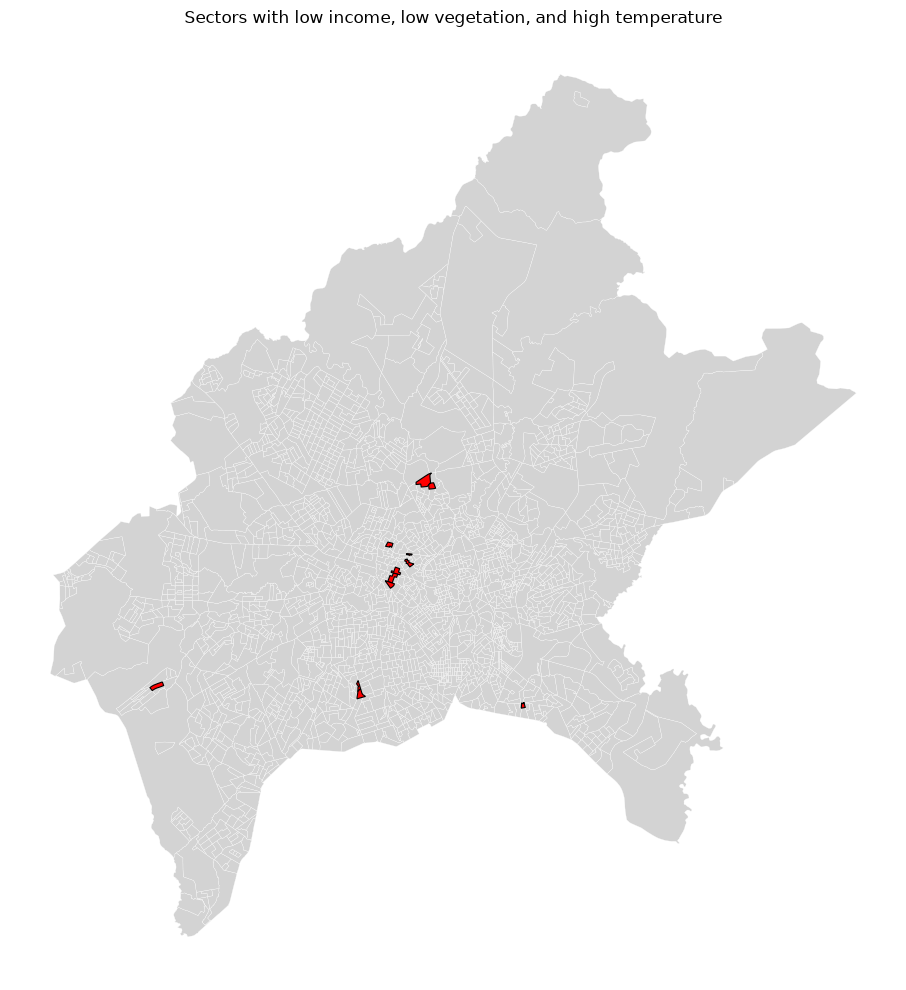

In [20]:
fig, ax = plt.subplots(figsize=(10, 10))

analysis.plot(
    ax=ax,
    color="lightgrey",
    edgecolor="white",
    linewidth=0.2,
)

analysis[
    analysis["overlap_thermal_inequality"]
].plot(
    ax=ax,
    color="red",
    edgecolor="black",
    linewidth=0.8,
)

ax.set_title(
    "Sectors with low income, low vegetation, and high temperature"
)
ax.set_axis_off()

plt.tight_layout()
plt.show()

In [21]:
analysis_output = PROCESSED / "sector_analysis.csv"

analysis.drop(columns="geometry").to_csv(
    analysis_output,
    index=False,
)

print(f"File saved: {analysis_output}")
print(f"Rows: {len(analysis)}")
print(f"Columns: {len(analysis.columns) - 1}")

File saved: ~/goiania-thermal-justice/data/processed/sector_analysis.csv
Rows: 2310
Columns: 26


In [22]:
analysis_gpkg_output = PROCESSED / "sector_analysis.gpkg"

analysis.to_file(
    analysis_gpkg_output,
    driver="GPKG",
)

print(f"Geographic file saved: {analysis_gpkg_output}")

Geographic file saved: ~/goiania-thermal-justice/data/processed/sector_analysis.gpkg


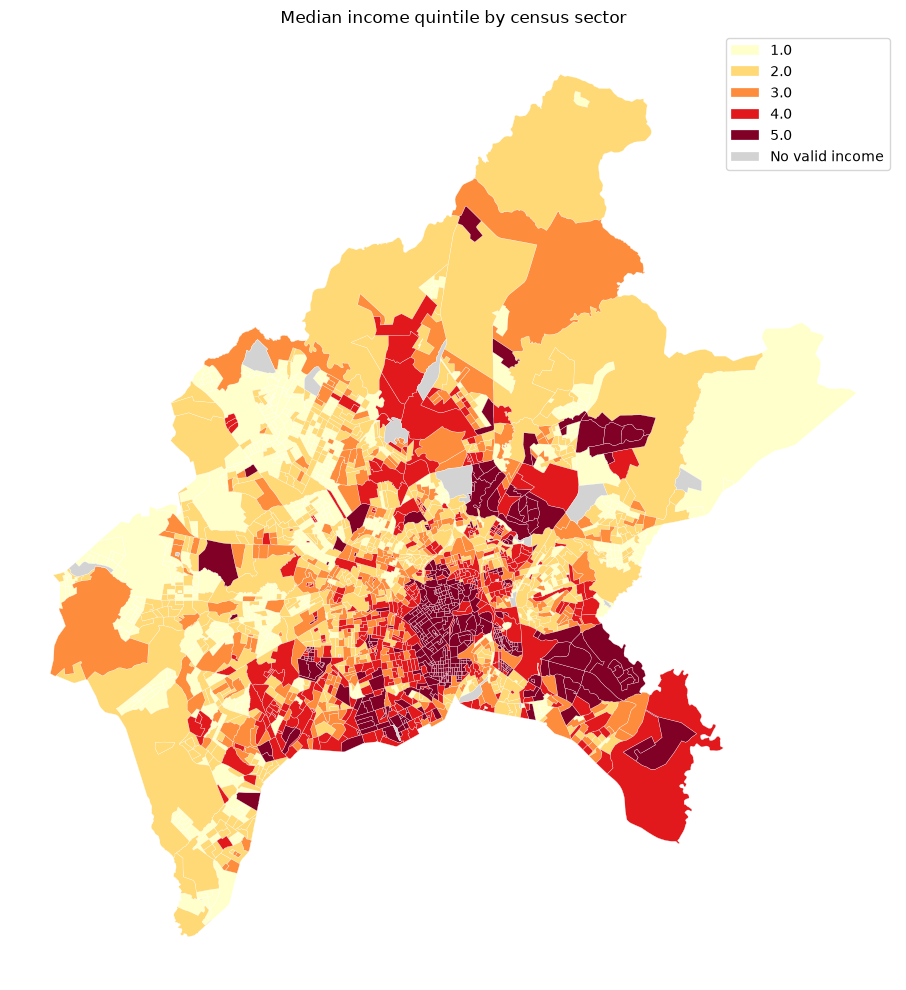

In [23]:
fig, ax = plt.subplots(figsize=(10, 10))

analysis.plot(
    ax=ax,
    column="income_quintile",
    cmap="YlOrRd",
    categorical=True,
    legend=True,
    edgecolor="white",
    linewidth=0.2,
    missing_kwds={
        "color": "lightgrey",
        "label": "No valid income",
    },
)

ax.set_title("Median income quintile by census sector")
ax.set_axis_off()

plt.tight_layout()
plt.show()

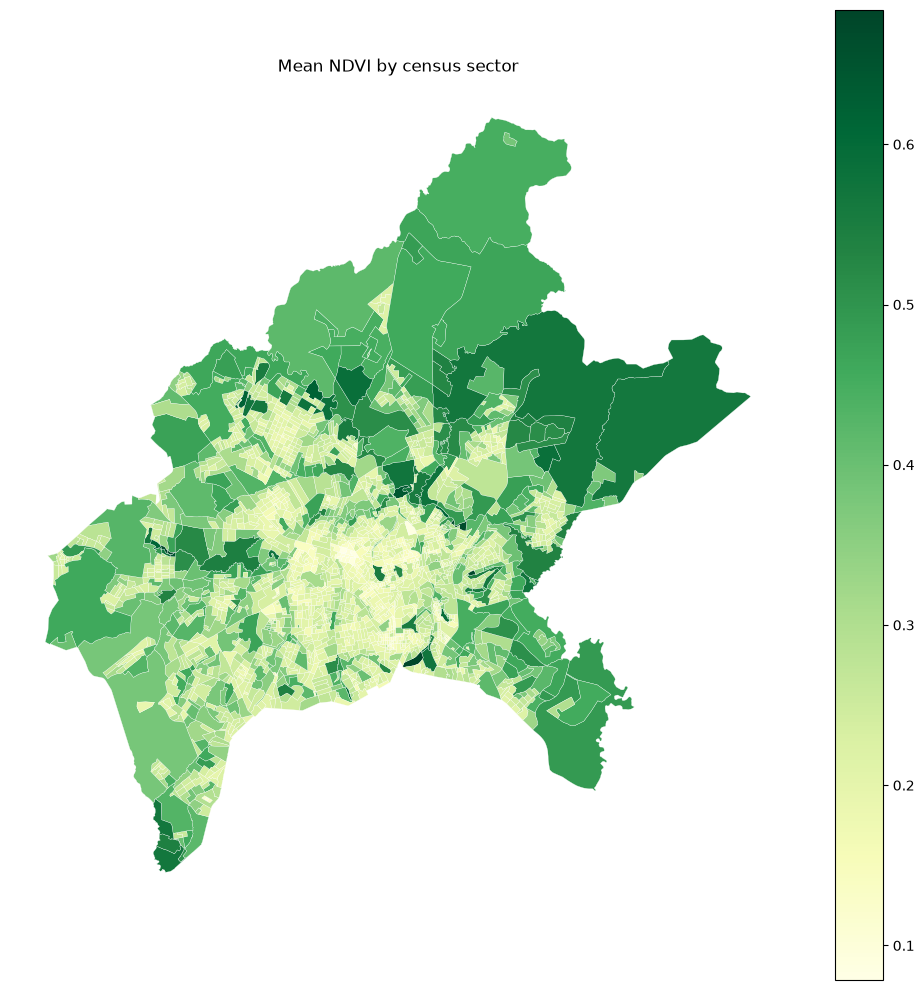

In [24]:
fig, ax = plt.subplots(figsize=(10, 10))

analysis.plot(
    ax=ax,
    column="ndvi",
    cmap="YlGn",
    legend=True,
    edgecolor="white",
    linewidth=0.2,
    missing_kwds={
        "color": "lightgrey",
        "label": "No NDVI data",
    },
)

ax.set_title("Mean NDVI by census sector")
ax.set_axis_off()

plt.tight_layout()
plt.show()


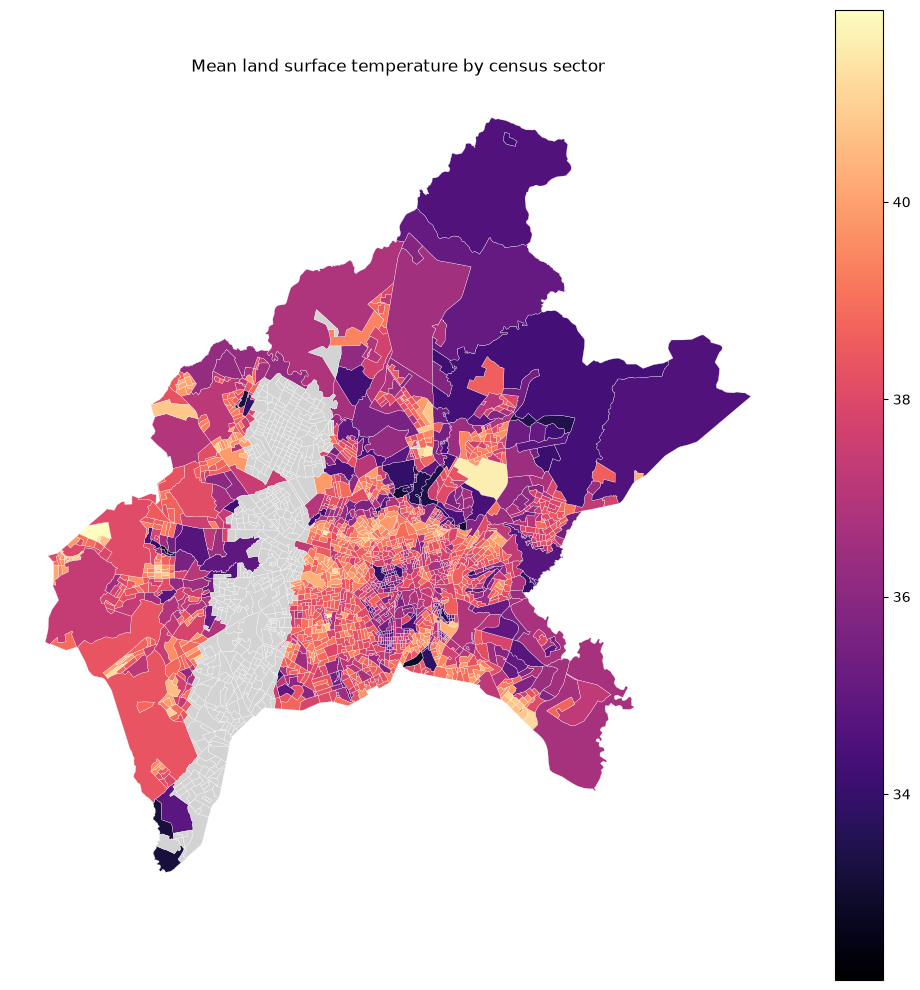

In [25]:
fig, ax = plt.subplots(figsize=(10, 10))

analysis.plot(
    ax=ax,
    column="lst_c",
    cmap="magma",
    legend=True,
    edgecolor="white",
    linewidth=0.2,
    missing_kwds={
        "color": "lightgrey",
        "label": "No valid LST",
    },
)

ax.set_title("Mean land surface temperature by census sector")
ax.set_axis_off()

plt.tight_layout()
plt.show()

In [26]:
web_columns = [
    "sector_id",
    "income_median",
    "income_quintile",
    "ndvi",
    "lst_c",
    "has_lst",
    "lst_data_status",
    "overlap_thermal_inequality",
    "is_rural",
    "small_sector",
    "geometry",
]

web_data = analysis[web_columns].copy()

web_data = web_data.to_crs("EPSG:31982")
web_data["geometry"] = web_data.geometry.simplify(
    tolerance=20,
    preserve_topology=True,
)

web_data = web_data.to_crs("EPSG:4326")

web_output = PROCESSED / "sectors_web.geojson"

web_data.to_file(
    web_output,
    driver="GeoJSON",
)

print(f"File saved: {web_output}")
print(f"Rows: {len(web_data)}")
print(f"Size: {web_output.stat().st_size / 1024 / 1024:.2f} MB")

File saved: ~/goiania-thermal-justice/data/processed/sectors_web.geojson
Rows: 2310
Size: 1.76 MB


In [27]:
web_check = gpd.read_file(web_output)

print("Shape:", web_check.shape)
print("CRS:", web_check.crs)
print("Columns:")
print(web_check.columns.tolist())
print("Invalid geometries:", (~web_check.geometry.is_valid).sum())
print("Missing geometries:", web_check.geometry.isna().sum())

Shape: (2310, 11)
CRS: EPSG:4326
Columns:
['sector_id', 'income_median', 'income_quintile', 'ndvi', 'lst_c', 'has_lst', 'lst_data_status', 'overlap_thermal_inequality', 'is_rural', 'small_sector', 'geometry']
Invalid geometries: 0
Missing geometries: 0


In [28]:
quintile_analysis.to_csv(
    PROCESSED / "income_quintile_analysis.csv",
    index=False,
)

income_band_analysis.to_csv(
    PROCESSED / "income_band_analysis.csv",
    index=False,
)

robust_quintile_analysis.to_csv(
    PROCESSED / "robust_quintile_analysis.csv",
    index=False,
)

correlation_tests.to_csv(
    PROCESSED / "correlation_tests.csv",
    index=False,
)

overlap_sectors.to_csv(
    PROCESSED / "overlap_sectors.csv",
    index=False,
)

print("Summary tables saved.")

Summary tables saved.


## Diagnóstico de temperatura alta

Esta seção resume valores altos de temperatura e sua distribuição por quintil. O limiar é usado como regra descritiva; TODO: justificar a escolha substantiva do corte.


In [29]:
valid_lst_values = analysis.loc[
    analysis["lst_c"].notna(),
    "lst_c",
]

high_lst_threshold = valid_lst_values.quantile(0.75)

analysis["high_lst"] = analysis["lst_c"].ge(high_lst_threshold)

high_lst_summary = (
    analysis[analysis["income_quintile"].notna()]
    .groupby("income_quintile")
    .agg(
        n_sectors=("sector_id", "count"),
        n_high_lst=("high_lst", "sum"),
    )
    .reset_index()
)

high_lst_summary["high_lst_pct"] = (
    high_lst_summary["n_high_lst"]
    / high_lst_summary["n_sectors"]
    * 100
).round(1)

print(f"High LST threshold: {high_lst_threshold:.2f} °C")
high_lst_summary

High LST threshold: 38.95 °C


,income_quintile,n_sectors,n_high_lst,high_lst_pct
0,1.0,500,110,22.0
1,2.0,602,155,25.7
2,3.0,335,90,26.9
3,4.0,394,72,18.3
4,5.0,458,19,4.1


In [30]:
high_lst_summary = (
    analysis[
        analysis["income_quintile"].notna()
        & analysis["lst_c"].notna()
    ]
    .groupby("income_quintile")
    .agg(
        n_valid_lst=("sector_id", "count"),
        n_high_lst=("high_lst", "sum"),
    )
    .reset_index()
)

high_lst_summary["high_lst_pct"] = (
    high_lst_summary["n_high_lst"]
    / high_lst_summary["n_valid_lst"]
    * 100
).round(1)

print(f"High LST threshold: {high_lst_threshold:.2f} °C")
high_lst_summary

High LST threshold: 38.95 °C


,income_quintile,n_valid_lst,n_high_lst,high_lst_pct
0,1.0,332,110,33.1
1,2.0,426,155,36.4
2,3.0,258,90,34.9
3,4.0,324,72,22.2
4,5.0,427,19,4.4


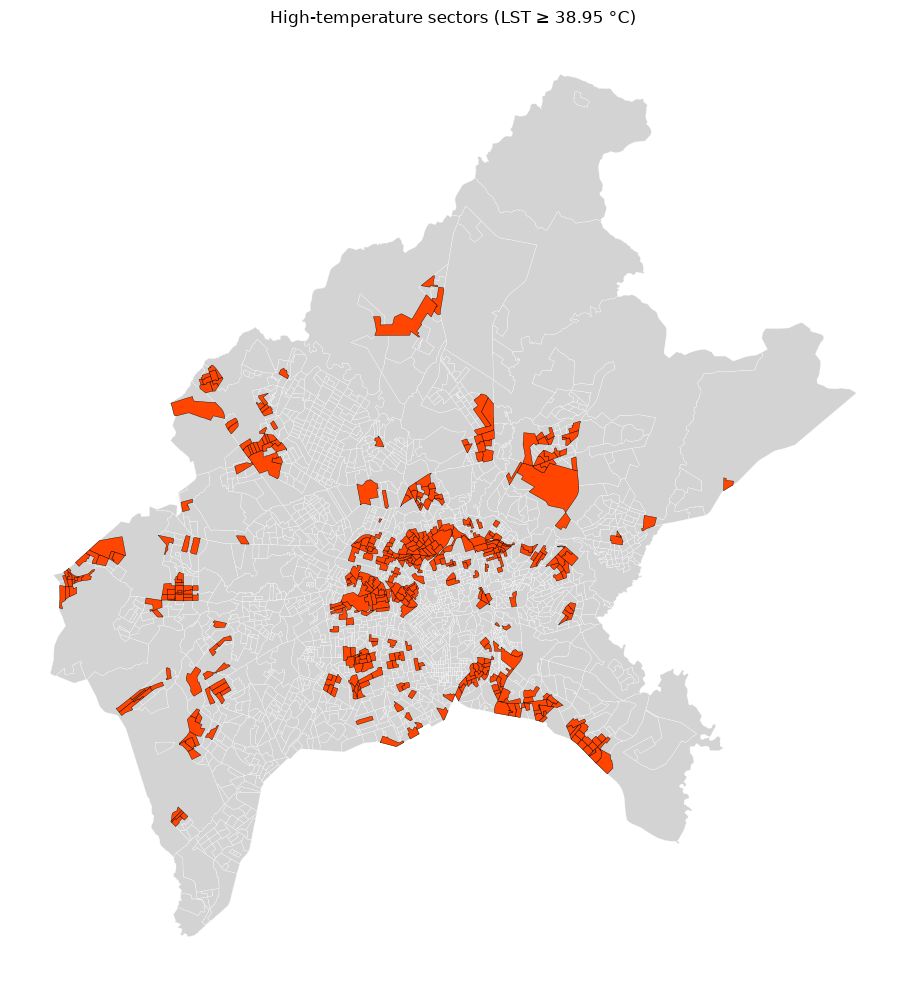

In [31]:
fig, ax = plt.subplots(figsize=(10, 10))

analysis.plot(
    ax=ax,
    color="lightgrey",
    edgecolor="white",
    linewidth=0.2,
)

analysis[
    analysis["high_lst"]
].plot(
    ax=ax,
    color="orangered",
    edgecolor="black",
    linewidth=0.3,
)

ax.set_title(
    f"High-temperature sectors (LST ≥ {high_lst_threshold:.2f} °C)"
)
ax.set_axis_off()

plt.tight_layout()
plt.show()

## Interseção entre baixa renda e alta temperatura

A tabela final localiza setores que atendem simultaneamente às regras de baixa renda e temperatura alta. A interpretação deve permanecer descritiva.


In [32]:
analysis["low_income_high_lst"] = (
    analysis["income_quintile"].eq(1)
    & analysis["high_lst"]
)

low_income_high_lst = analysis[
    analysis["low_income_high_lst"]
].copy()

print(
    "Low-income and high-temperature sectors:",
    len(low_income_high_lst),
)

Low-income and high-temperature sectors: 110


In [33]:
low_income_high_lst_summary = (
    low_income_high_lst
    .groupby("subdistrict")
    .agg(
        n_sectors=("sector_id", "count"),
        mean_lst_c=("lst_c", "mean"),
        mean_ndvi=("ndvi", "mean"),
    )
    .sort_values("n_sectors", ascending=False)
    .reset_index()
)

low_income_high_lst_summary

,subdistrict,n_sectors,mean_lst_c,mean_ndvi
0,U.T.P. Zona Rural,26,39.873975,0.250771
1,U.T.P. Mutirão e Curitiba,14,39.963060,0.251812
2,U.T.P. Vera Cruz,11,39.718421,0.240541
3,U.T.P. Jardim Primavera,8,39.951961,0.253562
4,U.T.P. Parque das Laranjeiras e Jardim da Luz,8,39.596575,0.252241
5,U.T.P. Jardim Guanabara,6,39.399595,0.242903
6,U.T.P. Urias Magalhães,5,39.513260,0.219168
7,U.T.P. Campinas,5,39.339386,0.154929
8,U.T.P. Vila Rizzo,4,39.265790,0.259338
9,U.T.P. Jardim Europa,4,39.285242,0.197154


In [34]:
import osmnx as ox

city_polygon = analysis.to_crs("EPSG:4326").geometry.union_all()

parks_osm = ox.features_from_polygon(
    city_polygon,
    tags={"leisure": "park"},
)

parks_osm = parks_osm.reset_index()

print("OSM elements:", len(parks_osm))
print(parks_osm.geometry.geom_type.value_counts())

OSM elements: 924
Polygon         892
MultiPolygon     30
Point             2
Name: count, dtype: int64


## Conclusão da etapa

A análise transforma os indicadores em comparações por renda, associações e mapas de setores extremos. Ela sustenta perguntas de desigualdade térmica, mas não estima efeitos causais.
